In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

from pyrite.experimental.quantum import propagate_planar_source, score_planar_source
from pyrite.quantum import (
    QuantumDynamics,
    QuantumNumerics,
    QuantumRegion,
    QuantumSetup,
    TransverseStateSpec,
)

# Planar channeling and radiation

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/13-planar-channeling-radiation.py)

Project a **1 Å** Gaussian into Si(110), evolve its populations over
**0.2 µm**, and score forward radiation at **17 MeV**.
This experimental CPU diagnostic uses a restricted finite basis;
its physical predictions are not rigorously validated.

In [ ]:
source = TransverseStateSpec.recipe("gaussian", waist_ang=1.0, dimension=1)
setup = QuantumSetup(
    region=QuantumRegion(kind="planar", plane_hkl=(1, 1, 0)),
    dynamics=QuantumDynamics(kind="channeling"),
    numerics=QuantumNumerics(basis_size=8, bloch_cells=4, step_ang=20.0),
)
entry = setup.project_state(
    source,
    crystal="silicon",
    kinetic_energy_eV=17e6,
    incidence_rad=0.0,
    impact="fixed",
)
depth_ang = 2_000.0

In [ ]:
history = propagate_planar_source(entry, depth_ang=depth_ang)

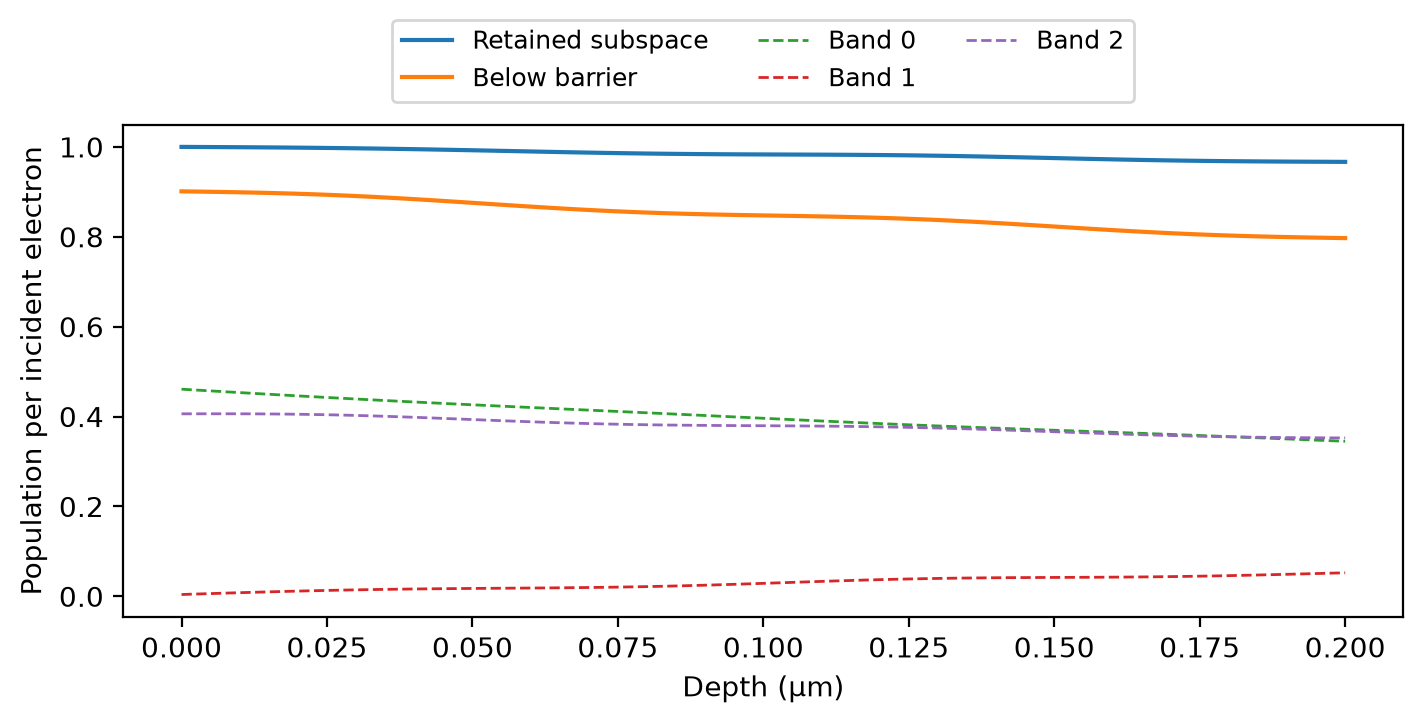

In [ ]:
fig_populations, _ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
_depth_um = history.z_ang / 10_000
_ax.plot(_depth_um, history.trace, label="Retained subspace")
_ax.plot(_depth_um, history.bound_population, label="Below barrier")
for _band in range(3):
    _ax.plot(_depth_um, history.band_populations[:, _band], "--", lw=1, label=f"Band {_band}")
_ax.set(xlabel="Depth (µm)", ylabel="Population per incident electron")
_ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, fontsize=9)
fig_populations  # noqa: B018 - displayed by marimo

In [ ]:
radiation = score_planar_source(
    entry,
    depth_ang=depth_ang,
    photon_energy_eV=np.linspace(1_000.0, 50_000.0, 1_025),
    theta_rad=0.0,
    sample_ang=100.0,
    absorption=False,
)

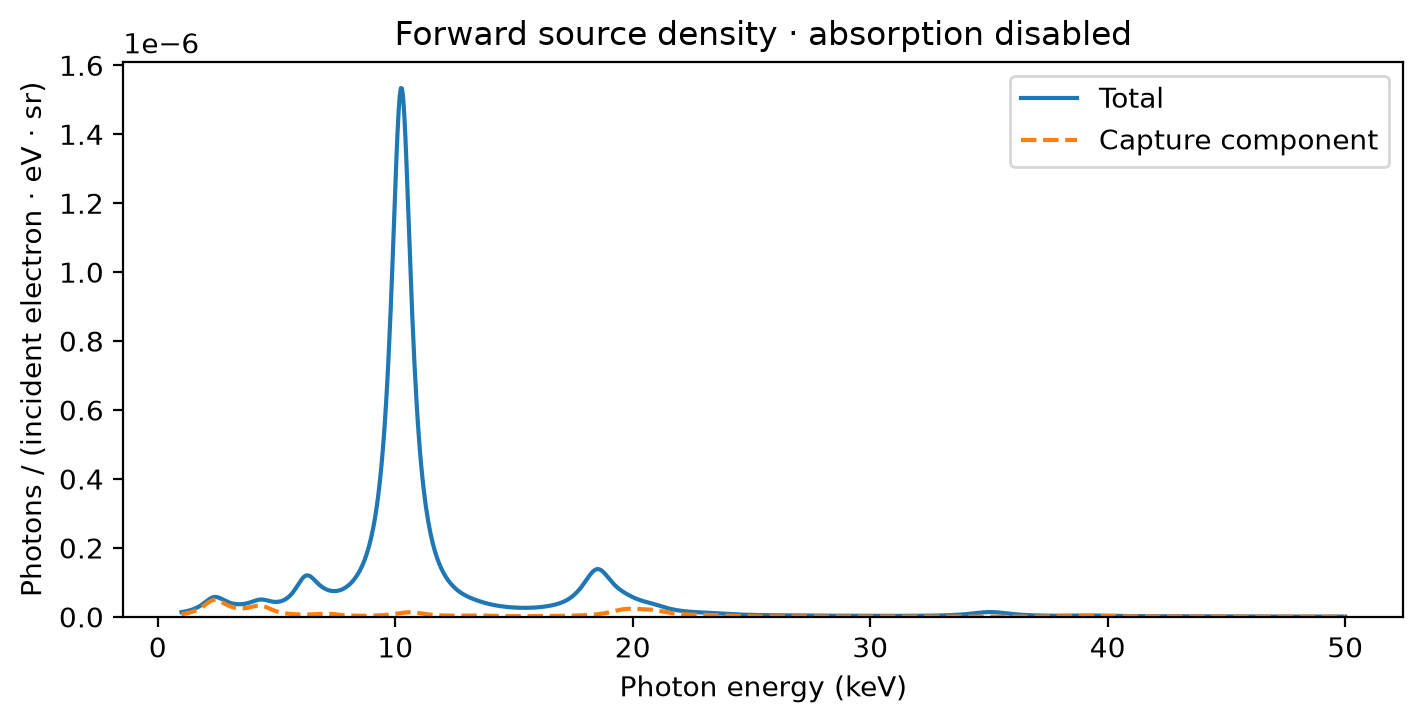

In [ ]:
fig_radiation, _ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
_ax.plot(radiation.photon_energy_eV / 1_000, radiation.spectrum, label="Total")
_ax.plot(
    radiation.photon_energy_eV / 1_000,
    radiation.capture_spectrum,
    "--",
    label="Capture component",
)
_ax.set(
    xlabel="Photon energy (keV)",
    ylabel="Photons / (incident electron · eV · sr)",
    title="Forward source density · absorption disabled",
    ylim=(0, None),
)
_ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
_ax.legend()
fig_radiation  # noqa: B018 - displayed by marimo

Populations are normalized to incident electrons, without conditioning on
survival. The spectrum includes capture, but no aperture, instrument
response or beam-charge scaling. Incidence is the effective refracted
angle to the planes, not laboratory tilt.

Try changing depth or incidence, then refine the basis and depth step.
This fixed-impact diagnostic is distinct from the restricted
lattice-averaged Gaussian admitted by production transport.

## Continue learning

Next: [Axial channeling and wavefunction evolution](14-axial-channeling-evolution.ipynb).
The [planar channeling how-to](../../guides/experimental-planar-channeling.md)
and [quantum reference](../../reference/quantum-api.md#planar-transport-and-source-contracts)
explain the direct diagnostic and production boundaries.
[Production source envelope](../../validation/channeling/cr-planar-conditional-source.md)
records the separate admission restrictions and remaining validation gaps.

{download}`Download canonical Marimo notebook <../13-planar-channeling-radiation.py>`